# E2 — Multi-head self-attention and image tokenization

Multi-head self-attention is implemented with basic tensor operations and compared with `torch.nn.MultiheadAttention`. Both versions use row, patch and CNN-stem tokenizers on Fashion-MNIST. The six configurations share a split and training schedule; each runs for 30 epochs with seeds 42–44.

AI assistance is documented in [AI_USE_REPORT.md](../AI_USE_REPORT.md).

## 1. Environment and settings

Device selection follows CUDA → MPS → CPU. All models train from scratch in FP32.

In [1]:
# Uncomment only if these packages are missing in the notebook environment.
# %pip install torch torchvision numpy pandas matplotlib scikit-learn

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import json
import math
import platform
import random
import time

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, RandomSampler
import torchvision
from torchvision.datasets import FashionMNIST as TorchFashionMNIST
from IPython.display import display


def choose_device(name="auto"):
    if name == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")
        if torch.backends.mps.is_available():
            return torch.device("mps")
        return torch.device("cpu")
    device = torch.device(name)
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable.")
    if device.type == "mps" and not torch.backends.mps.is_available():
        raise RuntimeError("MPS is unavailable.")
    return device


def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


DEVICE = choose_device("auto")
DATA_DIR = Path("data")
RUN_DIR = Path("runs") / "E2" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
SEEDS = [42, 43, 44]
SPLIT_SEED = 2026
EPOCHS = 30
BATCH_SIZE = 256
NUM_WORKERS = 0  # Portable for notebook-defined datasets, including macOS.
LR = 0.0003
WEIGHT_DECAY = 0.0001
CLIP_NORM = 1.0
DIM, HEADS, DEPTH, FFN_DIM = 64, 4, 2, 128
DROPOUT, PATCH_SIZE = 0.1, 4
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
CONFIGS = [{"id": f"e2_{tokenizer}_{backend}", "model": "transformer",
            "tokenizer": tokenizer, "backend": backend}
           for tokenizer in ["rows", "patches", "cnn"]
           for backend in ["manual", "torch"]]

# Keep precision comparable across the two attention implementations.
torch.set_default_dtype(torch.float32)
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark = False

RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / "figures").mkdir(exist_ok=True)
SETTINGS = dict(seeds=SEEDS, split_seed=SPLIT_SEED, epochs=EPOCHS,
                batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, lr=LR,
                weight_decay=WEIGHT_DECAY, clip_norm=CLIP_NORM,
                scheduler="CosineAnnealingLR", eta_min=LR * 0.01,
                dim=DIM, heads=HEADS, depth=DEPTH, ffn_dim=FFN_DIM,
                dropout=DROPOUT, patch_size=PATCH_SIZE, pooling="mean",
                precision="float32", configurations=CONFIGS,
                device=str(DEVICE), python=platform.python_version(),
                torch=torch.__version__, torchvision=torchvision.__version__,
                device_name=torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else str(DEVICE))
(RUN_DIR / "settings.json").write_text(json.dumps(SETTINGS, indent=2))
print("Device:", DEVICE, "| Output:", RUN_DIR)
display(pd.DataFrame(CONFIGS))

Device: cuda | Output: runs/E2/20261107T181821468703Z


,id,model,tokenizer,backend
0,e2_rows_manual,transformer,rows,manual
1,e2_rows_torch,transformer,rows,torch
2,e2_patches_manual,transformer,patches,manual
3,e2_patches_torch,transformer,patches,torch
4,e2_cnn_manual,transformer,cnn,manual
5,e2_cnn_torch,transformer,cnn,torch


## 2. Dataset and pixel distribution

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) contains 28×28 grayscale images of ten clothing classes, distributed in IDX image and label files. A stratified split with `random_state=2026` divides the official 60,000 train images into **54,000 train** and **6,000 validation** images. The official **10,000 test** images are evaluated after all training runs.

Pixel mean and population standard deviation are calculated on the train split. The same values are used to standardize validation and test images. This changes their scale and location; it does not make the pixel distribution Gaussian. No augmentation is applied.

In [3]:
class FashionMNIST(TorchFashionMNIST):
    # HTTPS mirror from the dataset owner; torchvision verifies its file checksums.
    mirrors = ["https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/",
               *TorchFashionMNIST.mirrors]


def channel_statistics(images, indices):
    total, squared, count = 0.0, 0.0, 0
    for start in range(0, len(indices), 2048):
        batch = images[torch.as_tensor(indices[start:start + 2048])].double() / 255
        total += batch.sum().item()
        squared += batch.square().sum().item()
        count += batch.numel()
    mean = total / count
    std = math.sqrt(max(squared / count - mean * mean, 0.0))
    if std <= 1e-12:
        raise ValueError("Training images have zero variance.")
    return mean, std


class NormalizedImages(Dataset):
    def __init__(self, images, labels, indices, mean, std):
        self.images, self.labels, self.indices = images, labels, indices
        self.mean, self.std = mean, std

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        original = int(self.indices[index])
        image = (self.images[original].unsqueeze(0).float() / 255 - self.mean) / self.std
        return image, int(self.labels[original]), original


def make_loader(dataset, shuffle=False, seed=0):
    sampler = RandomSampler(dataset, generator=torch.Generator().manual_seed(seed)) if shuffle else None
    return DataLoader(dataset, batch_size=BATCH_SIZE, sampler=sampler,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                      generator=torch.Generator().manual_seed(9017), drop_last=False)

In [4]:
base_train = FashionMNIST(str(DATA_DIR / "raw"), train=True, download=True)
labels = base_train.targets.numpy()
train_indices, validation_indices = train_test_split(
    np.arange(len(labels)), test_size=6000, random_state=SPLIT_SEED, stratify=labels,
)
train_indices = np.sort(train_indices)
validation_indices = np.sort(validation_indices)
assert (len(train_indices), len(validation_indices)) == (54000, 6000)
assert len(np.intersect1d(train_indices, validation_indices)) == 0
assert len(np.union1d(train_indices, validation_indices)) == 60000
mean, std = channel_statistics(base_train.data, train_indices)
train_set = NormalizedImages(base_train.data, base_train.targets, train_indices, mean, std)
validation_set = NormalizedImages(base_train.data, base_train.targets, validation_indices, mean, std)
np.savez_compressed(RUN_DIR / "split_indices.npz", train=train_indices, validation=validation_indices)
DATA_SETTINGS = dict(dataset="Fashion-MNIST", n_train=len(train_set),
                     n_validation=len(validation_set), n_test=10000,
                     split_seed=SPLIT_SEED, mean=mean, std=std)
(RUN_DIR / "data_settings.json").write_text(json.dumps(DATA_SETTINGS, indent=2))
print(f"Train: {len(train_set):,}; validation: {len(validation_set):,}; test reserved: 10,000")
print(f"Training pixel mean={mean:.6f}; standard deviation={std:.6f}")
counts = pd.DataFrame({"class": CLASS_NAMES,
                       "train": np.bincount(labels[train_indices], minlength=10),
                       "validation": np.bincount(labels[validation_indices], minlength=10)})
display(counts)
counts.to_csv(RUN_DIR / "class_counts.csv", index=False)

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  1%|          | 328k/26.4M [00:00<00:07, 3.27MB/s]

 11%|█         | 2.82M/26.4M [00:00<00:01, 15.9MB/s]

 34%|███▍      | 8.95M/26.4M [00:00<00:00, 30.6MB/s]

 73%|███████▎  | 19.4M/26.4M [00:00<00:00, 53.3MB/s]

100%|██████████| 26.4M/26.4M [00:00<00:00, 52.0MB/s]

... (4 outputs left out)

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 18.9MB/s]

Train: 54,000; validation: 6,000; test reserved: 10,000
Training pixel mean=0.285829; standard deviation=0.352922


,class,train,validation
0,T-shirt/top,5400,600
1,Trouser,5400,600
2,Pullover,5400,600
3,Dress,5400,600
4,Coat,5400,600
5,Sandal,5400,600
6,Shirt,5400,600
7,Sneaker,5400,600
8,Bag,5400,600
9,Ankle boot,5400,600


Before normalization: mean=0.285829, std=0.352922
After normalization: mean=0.000000, std=1.000000


,scale,mean,std
0,0 to 1,2.858292e-01,0.352922
1,standardized,2.775558e-16,1.000000


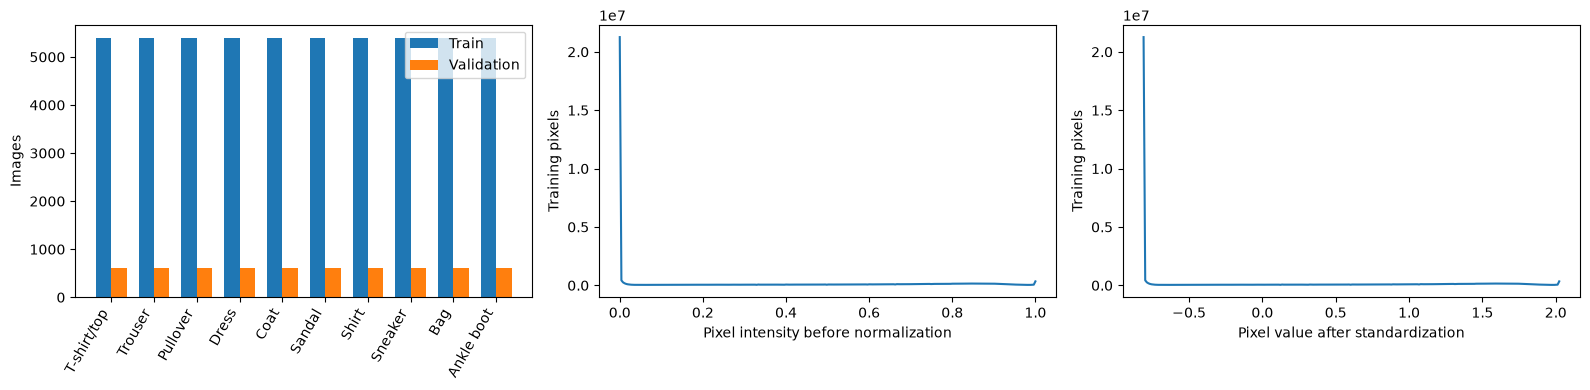

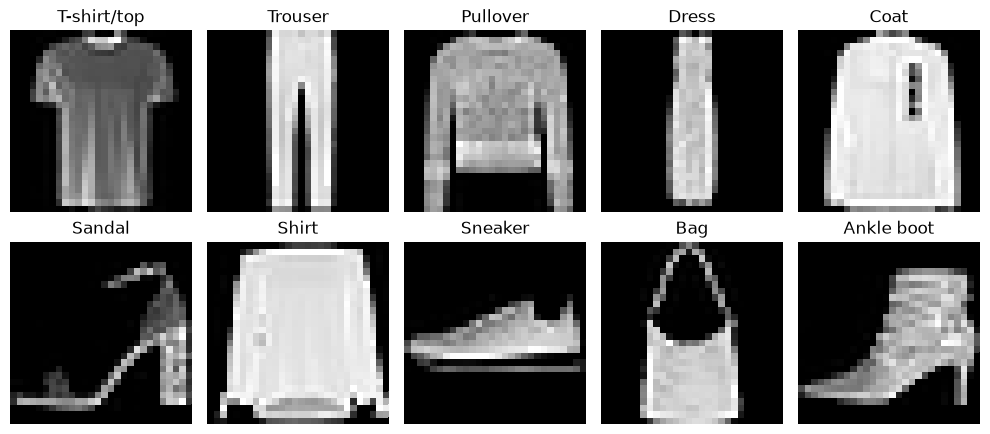

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
x = np.arange(10)
axes[0].bar(x - 0.18, counts["train"], 0.36, label="Train")
axes[0].bar(x + 0.18, counts["validation"], 0.36, label="Validation")
axes[0].set_xticks(x, CLASS_NAMES, rotation=60, ha="right")
axes[0].set_ylabel("Images")
axes[0].legend()
pixel_counts = torch.zeros(256, dtype=torch.int64)
for start in range(0, len(train_indices), 2048):
    pixels = base_train.data[torch.as_tensor(train_indices[start:start + 2048])]
    pixel_counts += torch.bincount(pixels.flatten().long(), minlength=256)
axes[1].plot(np.arange(256) / 255, pixel_counts.numpy())
axes[1].set(xlabel="Pixel intensity before normalization", ylabel="Training pixels")
pixel_values = np.arange(256) / 255
normalized_values = (pixel_values - mean) / std
weights = pixel_counts.numpy() / pixel_counts.sum().item()
normalized_mean = float(np.sum(weights * normalized_values))
normalized_std = float(np.sqrt(np.sum(weights * (normalized_values - normalized_mean) ** 2)))
axes[2].plot(normalized_values, pixel_counts.numpy())
axes[2].set(xlabel="Pixel value after standardization", ylabel="Training pixels")
print(f"Before normalization: mean={mean:.6f}, std={std:.6f}")
print(f"After normalization: mean={normalized_mean:.6f}, std={normalized_std:.6f}")
normalization_table = pd.DataFrame({"scale": ["0 to 1", "standardized"],
                                    "mean": [mean, normalized_mean],
                                    "std": [std, normalized_std]})
normalization_table.to_csv(RUN_DIR / "normalization_statistics.csv", index=False)
display(normalization_table)
fig.tight_layout()
fig.savefig(RUN_DIR / "figures" / "data_distribution.png", dpi=160)
plt.show()

rng = np.random.default_rng(SPLIT_SEED)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for label, ax in enumerate(axes.flat):
    index = int(rng.choice(train_indices[labels[train_indices] == label]))
    ax.imshow(base_train.data[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
fig.tight_layout()
fig.savefig(RUN_DIR / "figures" / "training_examples.png", dpi=160)
plt.show()

## 3. Image tokenizers

- **Rows:** 28 tokens, each containing one row of 28 pixels, projected to 64 dimensions.
- **Patches:** 49 non-overlapping 4×4 patches in row-major order, projected from 16 to 64 dimensions.
- **CNN stem:** two 3×3 stride-2 convolutions, with 32 and 64 channels, BatchNorm and ReLU. The 7×7 feature map gives 49 tokens.

The CNN stem changes both feature extraction and parameter count, so its comparison with the other tokenizers includes more than sequence length.

In [6]:
class ImageTokenizer(nn.Module):
    def __init__(self, kind, dim=64, patch_size=4):
        super().__init__()
        self.kind, self.patch_size = kind, patch_size
        if kind == "rows":
            self.num_tokens = 28
            self.project = nn.Linear(28, dim)
        elif kind == "patches":
            self.num_tokens = (28 // patch_size) ** 2
            self.project = nn.Linear(patch_size ** 2, dim)
        elif kind == "cnn":
            self.num_tokens = 49
            self.project = nn.Sequential(
                nn.Conv2d(1, 32, 3, stride=2, padding=1, bias=False),
                nn.BatchNorm2d(32), nn.ReLU(),
                nn.Conv2d(32, dim, 3, stride=2, padding=1, bias=False),
                nn.BatchNorm2d(dim), nn.ReLU())
        else:
            raise ValueError(f"Unknown tokenizer: {kind}")

    def forward(self, images):
        if self.kind == "cnn":
            return self.project(images).flatten(2).transpose(1, 2)
        if self.kind == "rows":
            tokens = images.squeeze(1)
        else:
            tokens = F.unfold(images, kernel_size=self.patch_size,
                              stride=self.patch_size).transpose(1, 2)
        return self.project(tokens)

## 4. Manual and PyTorch attention

For an input $X\in\mathbb{R}^{B\times T\times D}$, a linear layer produces $Q,K,V$. Each is divided into $H=4$ heads with $d_h=D/H=16$. Each head computes

$$A_h=\operatorname{softmax}(Q_hK_h^\top/\sqrt{d_h}),\qquad Z_h=A_hV_h.$$

The head outputs are concatenated and projected back to dimension 64. Dropout is applied to the attention weights during training. The manual version uses linear layers, matrix multiplication, softmax, and reshaping/concatenation. The reference uses `nn.MultiheadAttention` in a separate class. Its weights are copied from the manual implementation so paired runs have the same initialization.

In [7]:
class ManualSelfAttention(nn.Module):
    def __init__(self, dim=64, heads=4, dropout=0.1):
        super().__init__()
        if dim <= 0 or heads <= 0 or dim % heads:
            raise ValueError("Embedding dimension must be positive and divisible by heads.")
        self.dim, self.heads, self.head_dim = dim, heads, dim // heads
        self.dropout_p = dropout
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        self.attention_dropout = nn.Dropout(dropout)
        nn.init.xavier_uniform_(self.qkv.weight)
        nn.init.zeros_(self.qkv.bias)
        nn.init.xavier_uniform_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x):
        batch, tokens, dim = x.shape
        qkv = self.qkv(x).reshape(batch, tokens, 3, self.heads, self.head_dim)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(dim=0)
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        weights = self.attention_dropout(scores.softmax(dim=-1))
        context = (weights @ v).transpose(1, 2).reshape(batch, tokens, dim)
        return self.proj(context)


class TorchSelfAttention(nn.Module):
    def __init__(self, dim=64, heads=4, dropout=0.1):
        super().__init__()
        self.mha = nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)

    @classmethod
    def from_manual(cls, source):
        # Creating the reference must not alter initialization of later layers.
        with torch.random.fork_rng(devices=[]):
            target = cls(source.dim, source.heads, source.dropout_p)
        target = target.to(device=source.qkv.weight.device, dtype=source.qkv.weight.dtype)
        with torch.no_grad():
            target.mha.in_proj_weight.copy_(source.qkv.weight)
            target.mha.in_proj_bias.copy_(source.qkv.bias)
            target.mha.out_proj.weight.copy_(source.proj.weight)
            target.mha.out_proj.bias.copy_(source.proj.bias)
        return target

    def forward(self, x):
        return self.mha(x, x, x, need_weights=False)[0]

## 5. A shallow image classifier

Each token receives a learned positional embedding. Two pre-layer-normalized encoder blocks apply attention with a residual connection, followed by a 64 → 128 → 64 feed-forward network with GELU and dropout. A final layer normalization and mean over the token dimension feed a 10-class linear classifier. There is no CLS token.

The entire manual model is initialized first. Only its attention modules are replaced for the PyTorch version, preserving the other layers and the random-number stream.

In [8]:
class EncoderBlock(nn.Module):
    def __init__(self, dim=64, heads=4, dropout=0.1):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attention = ManualSelfAttention(dim, heads, dropout)
        self.dropout = nn.Dropout(dropout)
        self.ffn = nn.Sequential(nn.Linear(dim, 2 * dim), nn.GELU(),
                                 nn.Dropout(dropout), nn.Linear(2 * dim, dim),
                                 nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.dropout(self.attention(self.norm1(x)))
        return x + self.ffn(self.norm2(x))


class ImageTransformer(nn.Module):
    def __init__(self, tokenizer="patches", backend="manual", dim=64,
                 heads=4, depth=2, patch_size=4, dropout=0.1):
        super().__init__()
        self.tokenizer = ImageTokenizer(tokenizer, dim, patch_size)
        self.position = nn.Parameter(torch.empty(1, self.tokenizer.num_tokens, dim))
        nn.init.normal_(self.position, std=0.02)
        self.input_dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(dim, heads, dropout) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, 10)
        if backend == "torch":
            for block in self.blocks:
                block.attention = TorchSelfAttention.from_manual(block.attention)
        elif backend != "manual":
            raise ValueError(f"Unknown backend: {backend}")

    def forward(self, images):
        x = self.input_dropout(self.tokenizer(images) + self.position)
        for block in self.blocks:
            x = block(x)
        return self.head(self.norm(x).mean(dim=1))


def build_model(config):
    return ImageTransformer(config["tokenizer"], config["backend"],
                            DIM, HEADS, DEPTH, PATCH_SIZE, DROPOUT)


def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters())

## 6. Attention equivalence checks

With dropout disabled and matching weights, the two attention implementations are compared on forward outputs, input gradients and parameter gradients. The complete classifiers are also compared for each tokenizer. During training, backend kernels and dropout can lead to different optimization trajectories.

In [9]:
seed_everything(123)
manual = ManualSelfAttention(64, 4, dropout=0.0).double().eval()
reference = TorchSelfAttention.from_manual(manual).eval()
x_manual = torch.randn(2, 7, 64, dtype=torch.float64, requires_grad=True)
x_reference = x_manual.detach().clone().requires_grad_(True)
upstream = torch.randn_like(x_manual)
y_manual, y_reference = manual(x_manual), reference(x_reference)
(y_manual * upstream).sum().backward()
(y_reference * upstream).sum().backward()
torch.testing.assert_close(y_manual, y_reference, atol=1e-10, rtol=1e-9)
torch.testing.assert_close(x_manual.grad, x_reference.grad, atol=1e-10, rtol=1e-9)
parameter_pairs = [(manual.qkv.weight, reference.mha.in_proj_weight),
                   (manual.qkv.bias, reference.mha.in_proj_bias),
                   (manual.proj.weight, reference.mha.out_proj.weight),
                   (manual.proj.bias, reference.mha.out_proj.bias)]
for left, right in parameter_pairs:
    torch.testing.assert_close(left.grad, right.grad, atol=1e-10, rtol=1e-9)
print("Manual/native outputs, input gradients, and all parameter gradients agree.")

shape_rows = []
for kind, tokens in [("rows", 28), ("patches", 49), ("cnn", 49)]:
    seed_everything(42)
    left = ImageTransformer(kind, "manual").eval()
    seed_everything(42)
    right = ImageTransformer(kind, "torch").eval()
    images = torch.randn(2, 1, 28, 28)
    assert left.tokenizer(images).shape == (2, tokens, 64)
    torch.testing.assert_close(left(images), right(images), atol=2e-6, rtol=2e-5)
    assert left(images).shape == (2, 10)
    assert parameter_count(left) == parameter_count(right)
    shape_rows.append(dict(tokenizer=kind, tokens=tokens, embedding_dim=64,
                           n_parameters=parameter_count(left),
                           tokenizer_parameters=parameter_count(left.tokenizer),
                           attention_scores_per_image=DEPTH * HEADS * tokens * tokens))
model_cost = pd.DataFrame(shape_rows)
model_cost.to_csv(RUN_DIR / "model_cost.csv", index=False)
display(model_cost)
del manual, reference, left, right, x_manual, x_reference, y_manual, y_reference

Manual/native outputs, input gradients, and all parameter gradients agree.


,tokenizer,tokens,embedding_dim,n_parameters,tokenizer_parameters,attention_scores_per_image
0,rows,28,64,71370,1856,6272
1,patches,49,64,71946,1088,19208
2,cnn,49,64,89770,18912,19208


## 7. Training and validation

All configurations use AdamW with learning rate 0.0003, weight decay 0.0001, batch size 256 and gradient clipping at norm 1. A cosine schedule reduces the learning rate to 0.000003 over 30 epochs. Checkpoints maximize validation accuracy, with lower validation cross-entropy breaking ties.

Training time includes data loading and the synchronized forward/backward passes. The reported time per epoch is the median train time after the first epoch. Peak allocated GPU memory is measured on CUDA.

In [10]:
def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, count = 0.0, 0, 0
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats(DEVICE)
    synchronize(DEVICE)
    started = time.perf_counter()
    for images, labels, _ in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = F.cross_entropy(logits, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite training loss.")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM, error_if_nonfinite=True)
        optimizer.step()
        total_loss += loss.item() * labels.numel()
        correct += (logits.detach().argmax(1) == labels).sum().item()
        count += labels.numel()
    synchronize(DEVICE)
    seconds = time.perf_counter() - started
    peak = torch.cuda.max_memory_allocated(DEVICE) / 2**20 if DEVICE.type == "cuda" else None
    return dict(train_ce=total_loss / count, train_accuracy=correct / count,
                train_seconds=seconds, peak_memory_mib=peak)


@torch.inference_mode()
def validate(model, loader):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    synchronize(DEVICE)
    started = time.perf_counter()
    for images, labels, _ in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        total_loss += F.cross_entropy(logits, labels, reduction="sum").item()
        correct += (logits.argmax(1) == labels).sum().item()
        count += labels.numel()
    synchronize(DEVICE)
    return dict(val_ce=total_loss / count, val_accuracy=correct / count,
                validation_seconds=time.perf_counter() - started)

In [11]:
def train_one_run(config, seed):
    seed_everything(seed)
    directory = RUN_DIR / config["id"] / f"seed_{seed}"
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "settings.json").write_text(json.dumps(
        {**SETTINGS, **DATA_SETTINGS, "configuration": config, "seed": seed}, indent=2))
    model = build_model(config).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR * 0.01)
    train_loader = make_loader(train_set, shuffle=True, seed=seed)
    val_loader = make_loader(validation_set)
    history, best_accuracy, best_ce, best_epoch = [], -1.0, float("inf"), 0
    print(f"{config['id']} | seed={seed} | parameters={parameter_count(model):,}", flush=True)
    for epoch in range(1, EPOCHS + 1):
        learning_rate = optimizer.param_groups[0]["lr"]
        row = dict(epoch=epoch, learning_rate=learning_rate,
                   **train_epoch(model, train_loader, optimizer), **validate(model, val_loader))
        history.append(row)
        if row["val_accuracy"] > best_accuracy or (row["val_accuracy"] == best_accuracy and row["val_ce"] < best_ce):
            best_accuracy, best_ce, best_epoch = row["val_accuracy"], row["val_ce"], epoch
            torch.save({key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
                       directory / "best.pt")
        scheduler.step()
        pd.DataFrame(history).to_csv(directory / "history.csv", index=False)
        print(f"  {epoch:02d}/{EPOCHS}: train CE={row['train_ce']:.4f}, "
              f"train acc={row['train_accuracy']:.2%}, val CE={row['val_ce']:.4f}, "
              f"val acc={row['val_accuracy']:.2%}, {row['train_seconds']:.1f}s", flush=True)
    table = pd.DataFrame(history)
    summary = {**config, "seed": seed, "val_accuracy": best_accuracy,
               "val_ce": best_ce, "best_epoch": best_epoch, "n_parameters": parameter_count(model),
               "train_seconds": float(table.train_seconds.sum()),
               "seconds_per_epoch": float(table.train_seconds.iloc[1:].median()),
               "peak_memory_mib": float(table.peak_memory_mib.max()) if DEVICE.type == "cuda" else None}
    (directory / "training_summary.json").write_text(json.dumps(summary, indent=2))
    return summary

In [12]:
# Complete every training run before loading or evaluating the held-out test data.
training_rows = []
for config in CONFIGS:
    for seed in SEEDS:
        training_rows.append(train_one_run(config, seed))
training_results = pd.DataFrame(training_rows)
assert len(training_results) == len(CONFIGS) * len(SEEDS) == 18
training_results.to_csv(RUN_DIR / "validation_results.csv", index=False)
display(training_results[["id", "seed", "val_accuracy", "val_ce", "best_epoch", "train_seconds"]])
print("All 18 runs completed training and validation.", flush=True)

e2_rows_manual | seed=42 | parameters=71,370


  01/30: train CE=0.9215, train acc=69.98%, val CE=0.6025, val acc=78.50%, 1.6s


  02/30: train CE=0.5460, train acc=81.04%, val CE=0.4976, val acc=82.12%, 1.3s


  03/30: train CE=0.4707, train acc=83.49%, val CE=0.4789, val acc=82.83%, 1.3s


  04/30: train CE=0.4325, train acc=84.66%, val CE=0.4413, val acc=84.52%, 1.3s


  05/30: train CE=0.4086, train acc=85.45%, val CE=0.4210, val acc=85.32%, 1.3s


... (550 outputs left out)

  29/30: train CE=0.2535, train acc=90.85%, val CE=0.3067, val acc=89.32%, 1.4s


  30/30: train CE=0.2531, train acc=90.88%, val CE=0.3070, val acc=89.28%, 1.4s


,id,seed,val_accuracy,val_ce,best_epoch,train_seconds
0,e2_rows_manual,42,0.882167,0.337131,24,39.449188
1,e2_rows_manual,43,0.886667,0.325956,27,39.230243
2,e2_rows_manual,44,0.886667,0.327788,24,38.768087
3,e2_rows_torch,42,0.882500,0.333823,21,39.114984
4,e2_rows_torch,43,0.886167,0.329665,26,38.524625
5,e2_rows_torch,44,0.887000,0.327829,30,38.148554
6,e2_patches_manual,42,0.860833,0.376988,30,43.251106
7,e2_patches_manual,43,0.862167,0.376144,28,43.335817
8,e2_patches_manual,44,0.865167,0.366336,26,43.632375
9,e2_patches_torch,42,0.865167,0.376363,30,43.231937


All 18 runs completed training and validation.


## 8. Validation curves

Each line shows one seed, allowing the variation between runs to remain visible.

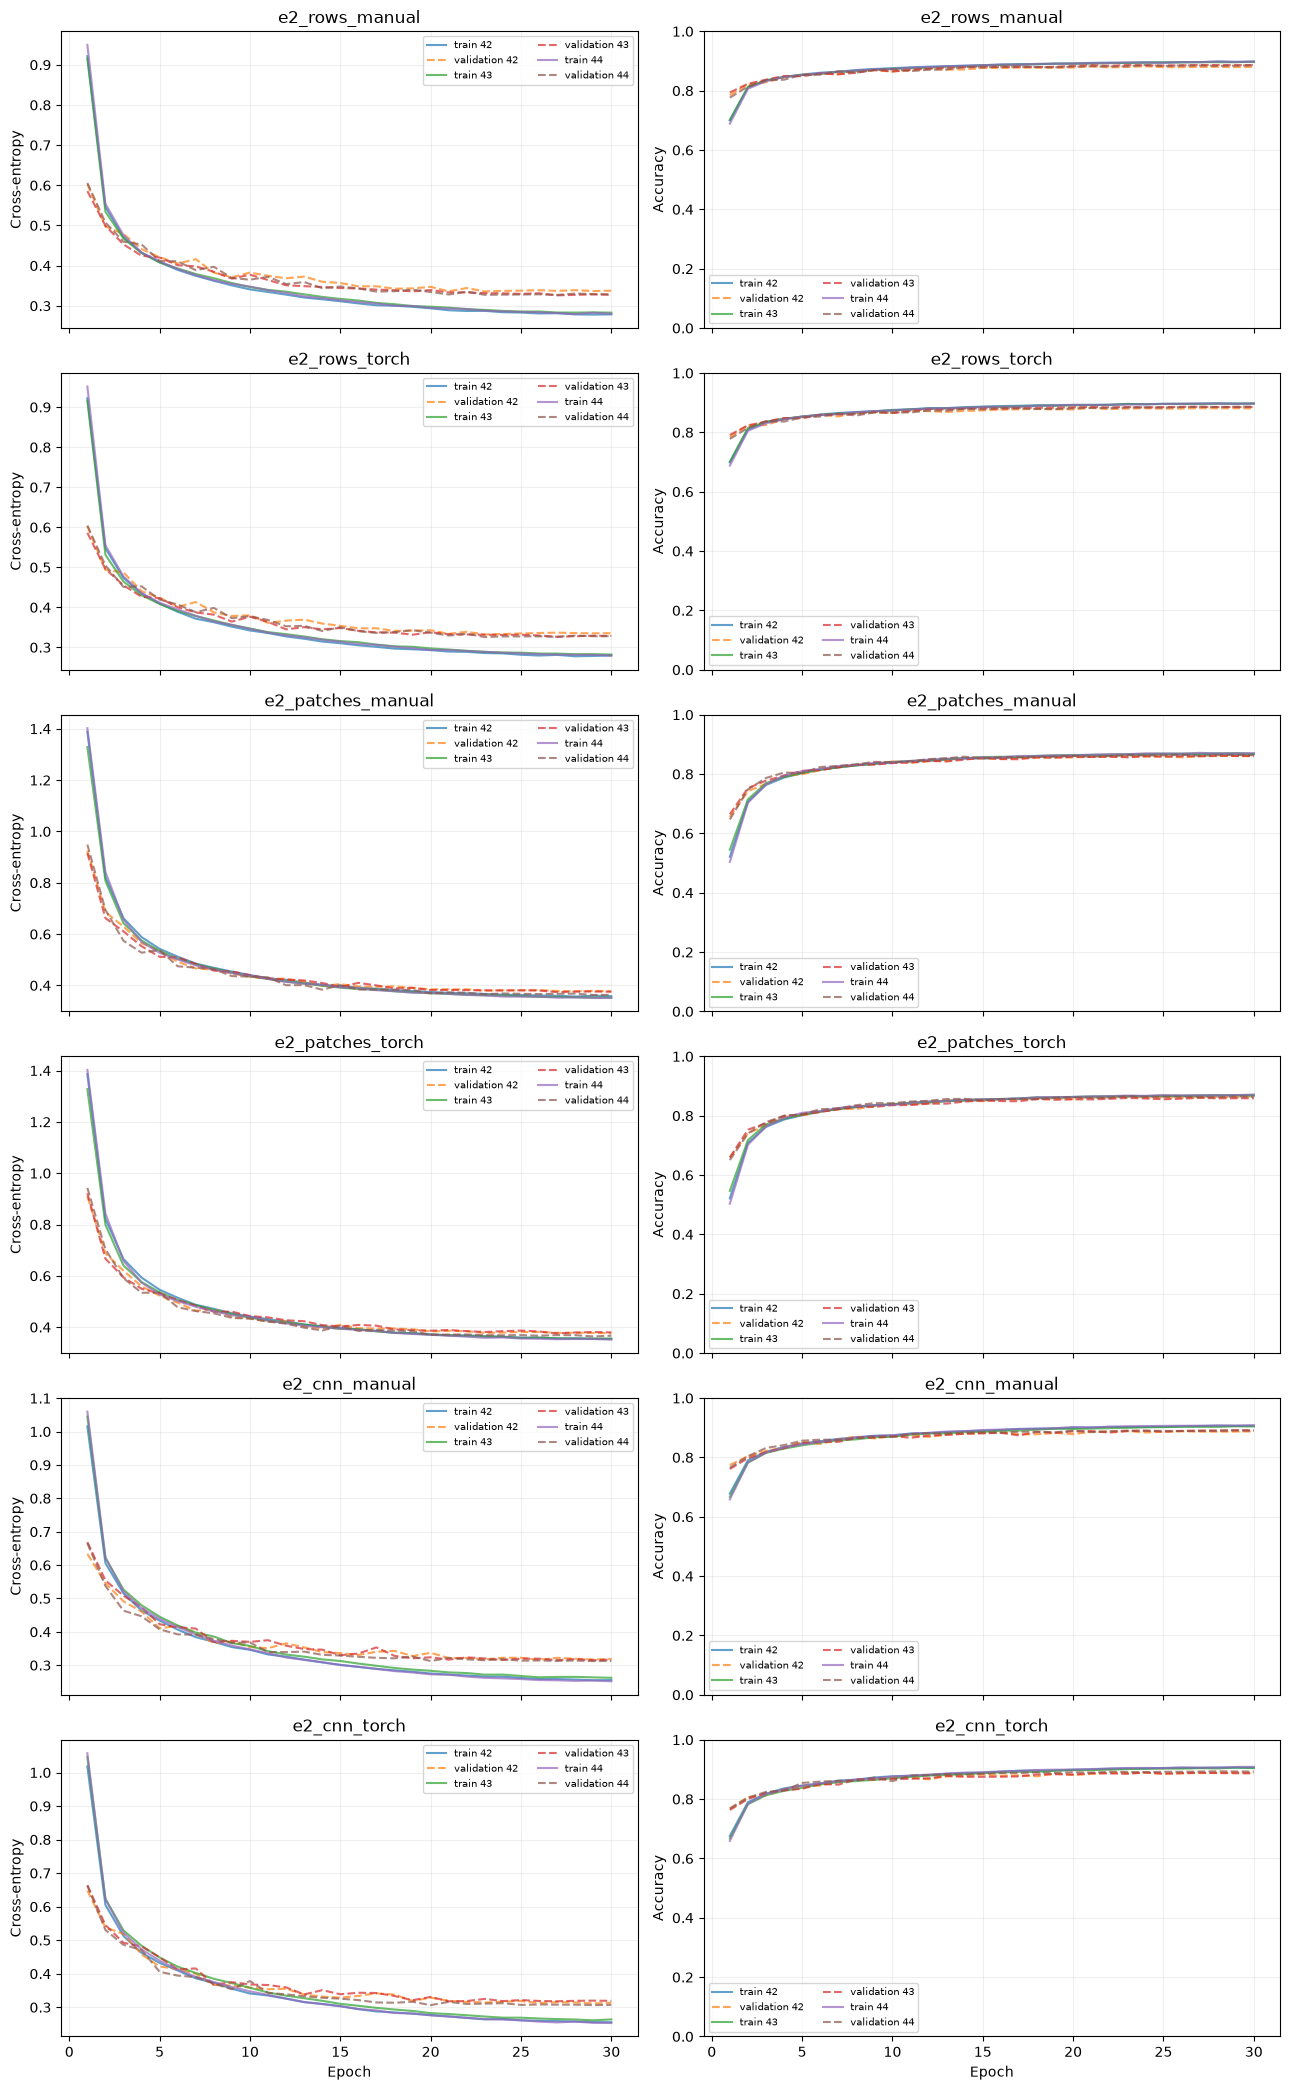

In [13]:
histories = {}
fig, axes = plt.subplots(6, 2, figsize=(13, 21), sharex=True)
for row, config in enumerate(CONFIGS):
    for seed in SEEDS:
        history = pd.read_csv(RUN_DIR / config["id"] / f"seed_{seed}" / "history.csv")
        histories[(config["id"], seed)] = history
        axes[row, 0].plot(history.epoch, history.train_ce, alpha=0.7, label=f"train {seed}")
        axes[row, 0].plot(history.epoch, history.val_ce, "--", alpha=0.7, label=f"validation {seed}")
        axes[row, 1].plot(history.epoch, history.train_accuracy, alpha=0.7, label=f"train {seed}")
        axes[row, 1].plot(history.epoch, history.val_accuracy, "--", alpha=0.7, label=f"validation {seed}")
    axes[row, 0].set(title=config["id"], ylabel="Cross-entropy")
    axes[row, 1].set(title=config["id"], ylabel="Accuracy", ylim=(0, 1))
    for ax in axes[row]:
        ax.legend(fontsize=7, ncol=2)
        ax.grid(alpha=0.2)
for ax in axes[-1]:
    ax.set_xlabel("Epoch")
fig.tight_layout()
fig.savefig(RUN_DIR / "figures" / "learning_curves.png", dpi=150)
plt.show()

## 9. Test evaluation

All 18 runs have finished. Each validation-selected checkpoint is evaluated on the full official test split. Accuracy, macro-F1, cross-entropy and per-class metrics are calculated from these predictions.

In [14]:
def metrics_from_confusion(confusion):
    true_positive = np.diag(confusion).astype(float)
    precision = np.divide(true_positive, confusion.sum(axis=0), out=np.zeros(10), where=confusion.sum(axis=0) != 0)
    recall = np.divide(true_positive, confusion.sum(axis=1), out=np.zeros(10), where=confusion.sum(axis=1) != 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros(10), where=precision + recall != 0)
    return true_positive.sum() / confusion.sum(), f1.mean(), precision, recall, f1


@torch.inference_mode()
def evaluate_test(model, loader):
    model.eval()
    predictions, total_loss = [], 0.0
    for images, labels, indices in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        probabilities = logits.softmax(1)
        confidence, predicted = probabilities.max(1)
        total_loss += F.cross_entropy(logits, labels, reduction="sum").item()
        predictions.append(pd.DataFrame({"index": indices.numpy(), "target": labels.cpu().numpy(),
                                          "prediction": predicted.cpu().numpy(),
                                          "confidence": confidence.cpu().numpy()}))
    table = pd.concat(predictions, ignore_index=True)
    confusion = np.bincount(10 * table.target.to_numpy() + table.prediction.to_numpy(),
                           minlength=100).reshape(10, 10)
    accuracy, macro_f1, precision, recall, f1 = metrics_from_confusion(confusion)
    per_class = pd.DataFrame({"class": CLASS_NAMES, "precision": precision,
                              "recall": recall, "f1": f1, "support": confusion.sum(1)})
    return table, confusion, per_class, dict(test_accuracy=accuracy,
                                            test_macro_f1=macro_f1, test_ce=total_loss / len(table))

In [15]:
assert len(training_rows) == 18 and all(row["best_epoch"] > 0 for row in training_rows)
base_test = FashionMNIST(str(DATA_DIR / "raw"), train=False, download=True)
assert len(base_test) == 10000
test_set = NormalizedImages(base_test.data, base_test.targets, np.arange(len(base_test)), mean, std)
test_loader = make_loader(test_set)
results, test_predictions, test_confusions = [], {}, {}
for config in CONFIGS:
    for seed in SEEDS:
        directory = RUN_DIR / config["id"] / f"seed_{seed}"
        model = build_model(config).to(DEVICE)
        model.load_state_dict(torch.load(directory / "best.pt", map_location=DEVICE, weights_only=True))
        predictions, confusion, per_class, metrics = evaluate_test(model, test_loader)
        assert len(predictions) == 10000 and confusion.sum() == 10000
        predictions.to_csv(directory / "test_predictions.csv", index=False)
        pd.DataFrame(confusion, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(directory / "test_confusion.csv")
        per_class.to_csv(directory / "test_per_class.csv", index=False)
        (directory / "test_metrics.json").write_text(json.dumps(metrics, indent=2))
        test_predictions[(config["id"], seed)] = predictions
        test_confusions[(config["id"], seed)] = confusion
        row = next(item for item in training_rows if item["id"] == config["id"] and item["seed"] == seed)
        results.append({**row, **metrics})
        print(f"{config['id']} | seed={seed}: test accuracy={metrics['test_accuracy']:.2%}, "
              f"macro-F1={metrics['test_macro_f1']:.4f}", flush=True)
results = pd.DataFrame(results)
RESULT_COLUMNS = ["id", "model", "tokenizer", "backend", "seed", "val_accuracy", "test_accuracy",
                  "test_macro_f1", "n_parameters", "train_seconds", "seconds_per_epoch",
                  "peak_memory_mib", "best_epoch"]
results[RESULT_COLUMNS].to_csv(RUN_DIR / "results.csv", index=False)
display(results[RESULT_COLUMNS])

e2_rows_manual | seed=42: test accuracy=87.78%, macro-F1=0.8773


e2_rows_manual | seed=43: test accuracy=88.02%, macro-F1=0.8799


e2_rows_manual | seed=44: test accuracy=88.07%, macro-F1=0.8807


e2_rows_torch | seed=42: test accuracy=87.89%, macro-F1=0.8788


e2_rows_torch | seed=43: test accuracy=87.91%, macro-F1=0.8788


e2_rows_torch | seed=44: test accuracy=88.17%, macro-F1=0.8813


... (9 outputs left out)

e2_cnn_torch | seed=42: test accuracy=88.42%, macro-F1=0.8842


e2_cnn_torch | seed=43: test accuracy=88.48%, macro-F1=0.8838


e2_cnn_torch | seed=44: test accuracy=89.02%, macro-F1=0.8901


,id,model,tokenizer,backend,seed,val_accuracy,test_accuracy,test_macro_f1,n_parameters,train_seconds,seconds_per_epoch,peak_memory_mib,best_epoch
0,e2_rows_manual,transformer,rows,manual,42,0.882167,0.8778,0.877328,71370,39.449188,1.325552,87.957520,24
1,e2_rows_manual,transformer,rows,manual,43,0.886667,0.8802,0.879921,71370,39.230243,1.326105,87.957520,27
2,e2_rows_manual,transformer,rows,manual,44,0.886667,0.8807,0.880721,71370,38.768087,1.293274,87.957520,24
3,e2_rows_torch,transformer,rows,torch,42,0.882500,0.8789,0.878752,71370,39.114984,1.320279,82.169922,21
4,e2_rows_torch,transformer,rows,torch,43,0.886167,0.8791,0.878792,71370,38.524625,1.306601,82.169922,26
5,e2_rows_torch,transformer,rows,torch,44,0.887000,0.8817,0.881304,71370,38.148554,1.307070,82.169922,30
6,e2_patches_manual,transformer,patches,manual,42,0.860833,0.8590,0.858678,71946,43.251106,1.443736,158.257812,30
7,e2_patches_manual,transformer,patches,manual,43,0.862167,0.8601,0.860278,71946,43.335817,1.450711,158.257812,28
8,e2_patches_manual,transformer,patches,manual,44,0.865167,0.8615,0.861745,71946,43.632375,1.458407,158.257812,26
9,e2_patches_torch,transformer,patches,torch,42,0.865167,0.8585,0.858089,71946,43.231937,1.458026,121.300781,30


## 10. Tokenizer and backend comparisons

Tables report the mean and sample SD across three seeds. Paired backend differences subtract the manual result from the PyTorch result at the same seed and tokenizer. Attention-score counts measure the quadratic attention term, rather than full model FLOPs.

In [16]:
metrics = ["test_accuracy", "test_macro_f1", "val_accuracy", "n_parameters",
           "train_seconds", "seconds_per_epoch", "peak_memory_mib", "best_epoch"]
summary = results.groupby(["id", "tokenizer", "backend"])[metrics].agg(["mean", "std"])
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary = summary.reset_index()
summary.to_csv(RUN_DIR / "summary.csv", index=False)
display(summary)

paired_rows = []
for tokenizer in ["rows", "patches", "cnn"]:
    subset = results[results.tokenizer == tokenizer]
    manual = subset[subset.backend == "manual"].set_index("seed")
    native = subset[subset.backend == "torch"].set_index("seed")
    for seed in SEEDS:
        paired_rows.append({"tokenizer": tokenizer, "seed": seed,
                            "accuracy_delta_pp": 100 * (native.loc[seed, "test_accuracy"] - manual.loc[seed, "test_accuracy"]),
                            "macro_f1_delta": native.loc[seed, "test_macro_f1"] - manual.loc[seed, "test_macro_f1"],
                            "native_over_manual_time": native.loc[seed, "seconds_per_epoch"] / manual.loc[seed, "seconds_per_epoch"]})
paired = pd.DataFrame(paired_rows)
paired.to_csv(RUN_DIR / "paired_attention_comparison.csv", index=False)
display(paired.groupby("tokenizer")[["accuracy_delta_pp", "macro_f1_delta", "native_over_manual_time"]].agg(["mean", "std"]))

tokenizer_comparison = results.groupby(["tokenizer", "backend"])[["test_accuracy", "test_macro_f1", "seconds_per_epoch"]].agg(["mean", "std"])
tokenizer_comparison.to_csv(RUN_DIR / "tokenizer_comparison.csv")
display(tokenizer_comparison)
display(model_cost)

,id,tokenizer,backend,test_accuracy_mean,test_accuracy_std,test_macro_f1_mean,test_macro_f1_std,val_accuracy_mean,val_accuracy_std,n_parameters_mean,n_parameters_std,train_seconds_mean,train_seconds_std,seconds_per_epoch_mean,seconds_per_epoch_std,peak_memory_mib_mean,peak_memory_mib_std,best_epoch_mean,best_epoch_std
0,e2_cnn_manual,cnn,manual,0.887000,0.006089,0.886791,0.005920,0.890444,0.001686,89770.0,0.0,40.338541,0.805778,1.366459,0.014252,176.080078,0.0,27.000000,3.464102
1,e2_cnn_torch,cnn,torch,0.886400,0.003305,0.886021,0.003560,0.891056,0.002411,89770.0,0.0,41.093362,1.328320,1.365650,0.055699,139.123047,0.0,27.000000,2.645751
2,e2_patches_manual,patches,manual,0.860200,0.001253,0.860234,0.001534,0.862722,0.002219,71946.0,0.0,43.406433,0.200203,1.450951,0.007338,158.257812,0.0,28.000000,2.000000
3,e2_patches_torch,patches,torch,0.860200,0.001539,0.859993,0.001673,0.863778,0.003155,71946.0,0.0,43.301302,0.806770,1.463978,0.013163,121.300781,0.0,26.666667,3.511885
4,e2_rows_manual,rows,manual,0.879567,0.001550,0.879323,0.001774,0.885167,0.002598,71370.0,0.0,39.149173,0.347713,1.314977,0.018798,87.957520,0.0,25.000000,1.732051
5,e2_rows_torch,rows,torch,0.879900,0.001562,0.879616,0.001462,0.885222,0.002394,71370.0,0.0,38.596054,0.487158,1.311317,0.007765,82.169922,0.0,25.666667,4.509250


accuracy_delta_pp           macro_f1_delta            \
                       mean       std           mean       std   
tokenizer                                                        
cnn           -6.000000e-02  0.301993      -0.000770  0.002943   
patches        3.700743e-15  0.050000      -0.000241  0.000544   
rows           3.333333e-02  0.124231       0.000293  0.001300   

          native_over_manual_time            
                             mean       std  
tokenizer                                    
cnn                      0.999411  0.039461  
patches                  1.009000  0.011022  
rows                     0.997327  0.012738

test_accuracy           test_macro_f1            \
                           mean       std          mean       std   
tokenizer backend                                                   
cnn       manual       0.887000  0.006089      0.886791  0.005920   
          torch        0.886400  0.003305      0.886021  0.003560   
patches   manual       0.860200  0.001253      0.860234  0.001534   
          torch        0.860200  0.001539      0.859993  0.001673   
rows      manual       0.879567  0.001550      0.879323  0.001774   
          torch        0.879900  0.001562      0.879616  0.001462   

                  seconds_per_epoch            
                               mean       std  
tokenizer backend                              
cnn       manual           1.366459  0.014252  
          torch            1.365650  0.055699  
patches   manual           1.450951  0.007338  
          torch            1.463978  0.013163  
rows      manual           1.314977  0.018798  
          torch            1.311317  0.007765

,tokenizer,tokens,embedding_dim,n_parameters,tokenizer_parameters,attention_scores_per_image
0,rows,28,64,71370,1856,6272
1,patches,49,64,71946,1088,19208
2,cnn,49,64,89770,18912,19208


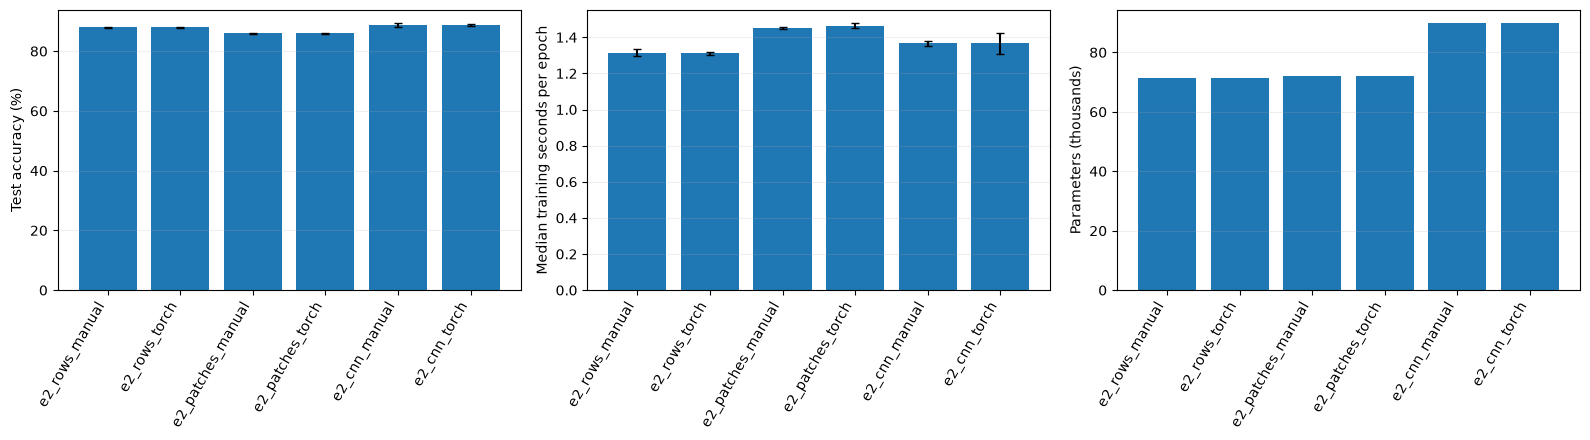

In [17]:
plot_data = results.groupby("id").agg(accuracy=("test_accuracy", "mean"),
                                       accuracy_sd=("test_accuracy", "std"),
                                       seconds=("seconds_per_epoch", "mean"),
                                       seconds_sd=("seconds_per_epoch", "std"),
                                       parameters=("n_parameters", "mean")).reindex([c["id"] for c in CONFIGS])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x = np.arange(len(plot_data))
axes[0].bar(x, 100 * plot_data.accuracy, yerr=100 * plot_data.accuracy_sd, capsize=3)
axes[0].set_ylabel("Test accuracy (%)")
axes[1].bar(x, plot_data.seconds, yerr=plot_data.seconds_sd, capsize=3)
axes[1].set_ylabel("Median training seconds per epoch")
axes[2].bar(x, plot_data.parameters / 1000)
axes[2].set_ylabel("Parameters (thousands)")
for ax in axes:
    ax.set_xticks(x, plot_data.index, rotation=60, ha="right")
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(RUN_DIR / "figures" / "accuracy_time_parameters.png", dpi=160)
plt.show()

## 11. Confusion matrices and errors

All examples use seed 42. Rows in the confusion matrices are true labels and columns are predicted labels. Error galleries show up to eight incorrect predictions with the highest confidence.

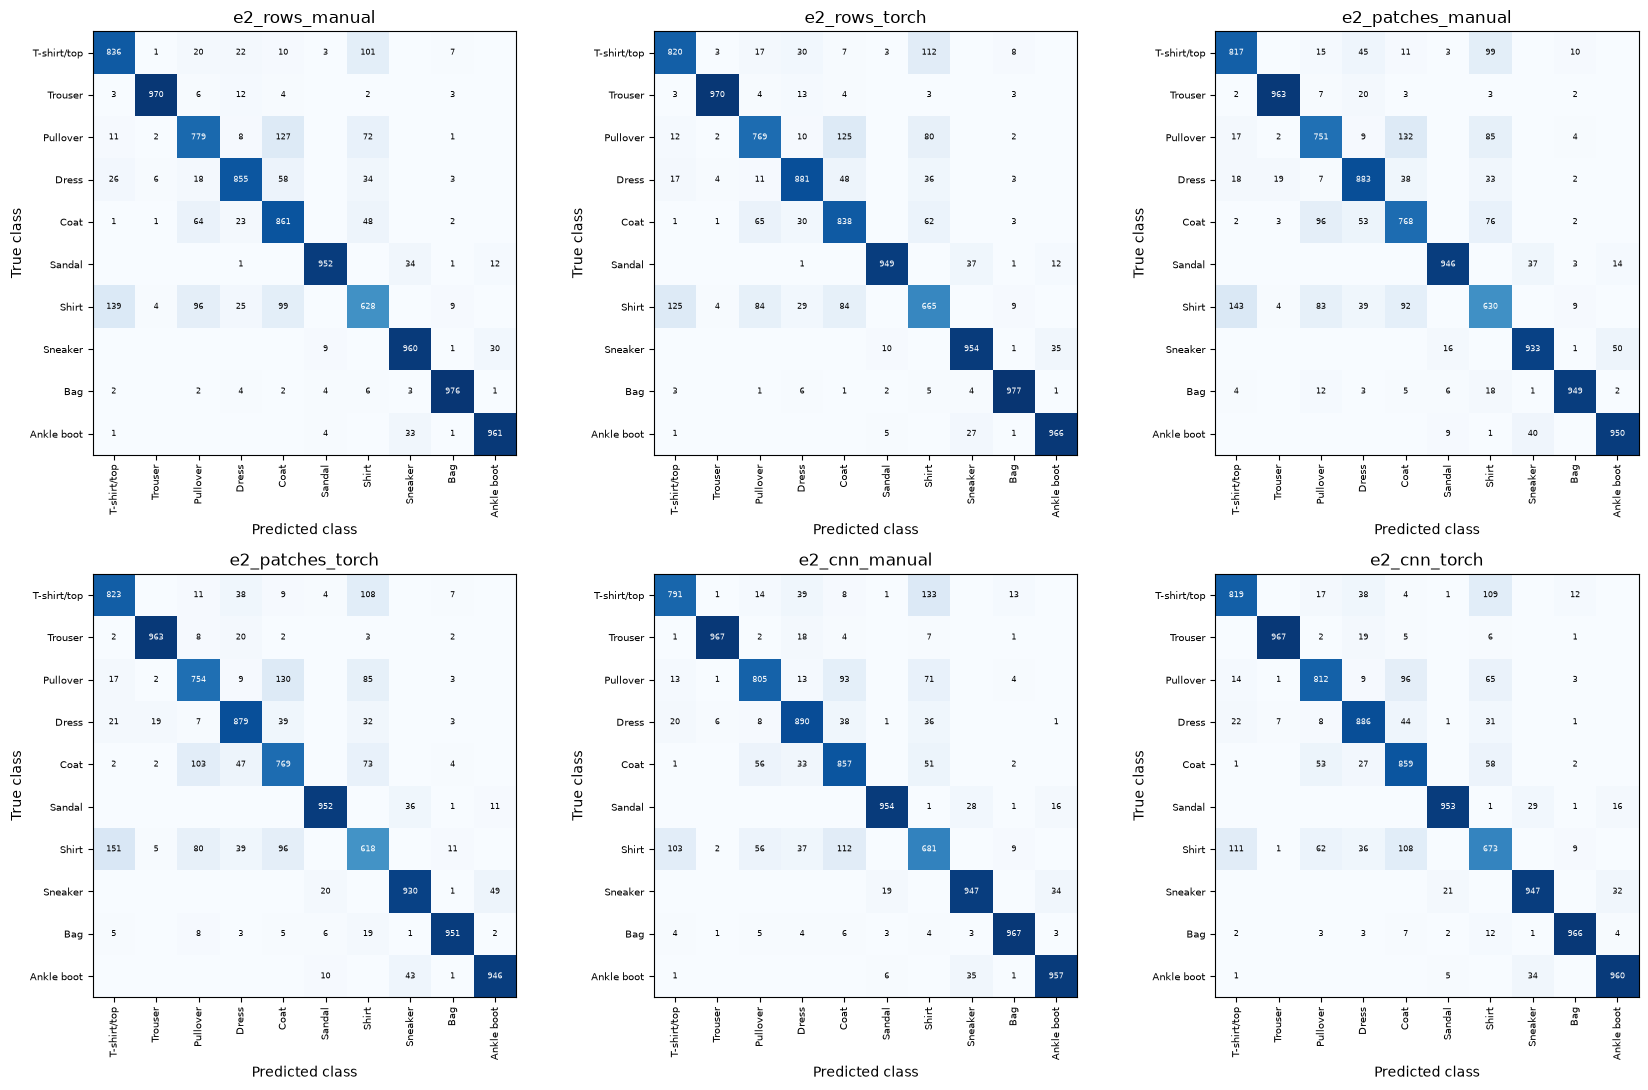

,id,seed,true_class,predicted_class,count
0,e2_rows_manual,42,Shirt,T-shirt/top,139
1,e2_rows_manual,42,Pullover,Coat,127
2,e2_rows_manual,42,T-shirt/top,Shirt,101
3,e2_rows_manual,42,Shirt,Coat,99
4,e2_rows_manual,42,Shirt,Pullover,96
5,e2_rows_torch,42,Pullover,Coat,125
6,e2_rows_torch,42,Shirt,T-shirt/top,125
7,e2_rows_torch,42,T-shirt/top,Shirt,112
8,e2_rows_torch,42,Shirt,Coat,84
9,e2_rows_torch,42,Shirt,Pullover,84


In [18]:
REPRESENTATIVE_SEED = min(SEEDS)
fig, axes = plt.subplots(2, 3, figsize=(17, 11))
confusion_pairs = []
for config, ax in zip(CONFIGS, axes.flat):
    confusion = test_confusions[(config["id"], REPRESENTATIVE_SEED)]
    image = ax.imshow(confusion, cmap="Blues", vmin=0, vmax=1000)
    ax.set(title=config["id"], xlabel="Predicted class", ylabel="True class")
    ax.set_xticks(range(10), CLASS_NAMES, rotation=90, fontsize=7)
    ax.set_yticks(range(10), CLASS_NAMES, fontsize=7)
    for true_label in range(10):
        for predicted_label in range(10):
            if confusion[true_label, predicted_label] > 0:
                ax.text(predicted_label, true_label, str(confusion[true_label, predicted_label]),
                        ha="center", va="center", fontsize=6,
                        color="white" if confusion[true_label, predicted_label] > 500 else "black")
    off_diagonal = confusion.copy()
    np.fill_diagonal(off_diagonal, 0)
    for flat_index in np.argsort(off_diagonal.ravel())[::-1][:5]:
        true_label, predicted_label = np.unravel_index(flat_index, (10, 10))
        confusion_pairs.append(dict(id=config["id"], seed=REPRESENTATIVE_SEED,
                                    true_class=CLASS_NAMES[true_label], predicted_class=CLASS_NAMES[predicted_label],
                                    count=int(confusion[true_label, predicted_label])))
fig.tight_layout()
fig.savefig(RUN_DIR / "figures" / "test_confusions_seed42.png", dpi=170)
plt.show()
confusion_pairs = pd.DataFrame(confusion_pairs)
confusion_pairs.to_csv(RUN_DIR / "frequent_confusions_seed42.csv", index=False)
display(confusion_pairs)

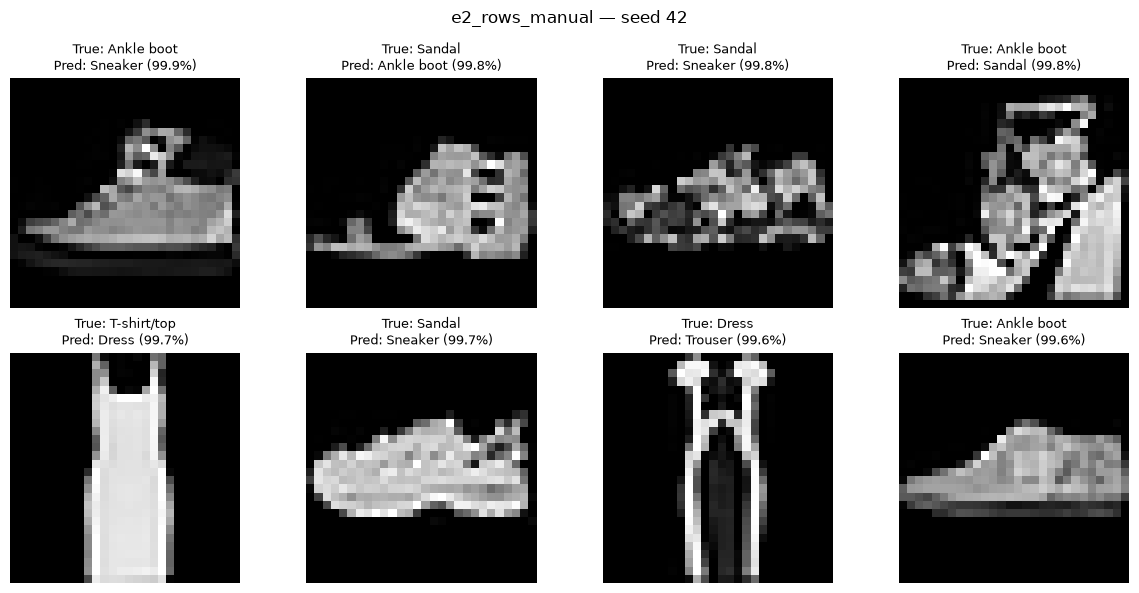

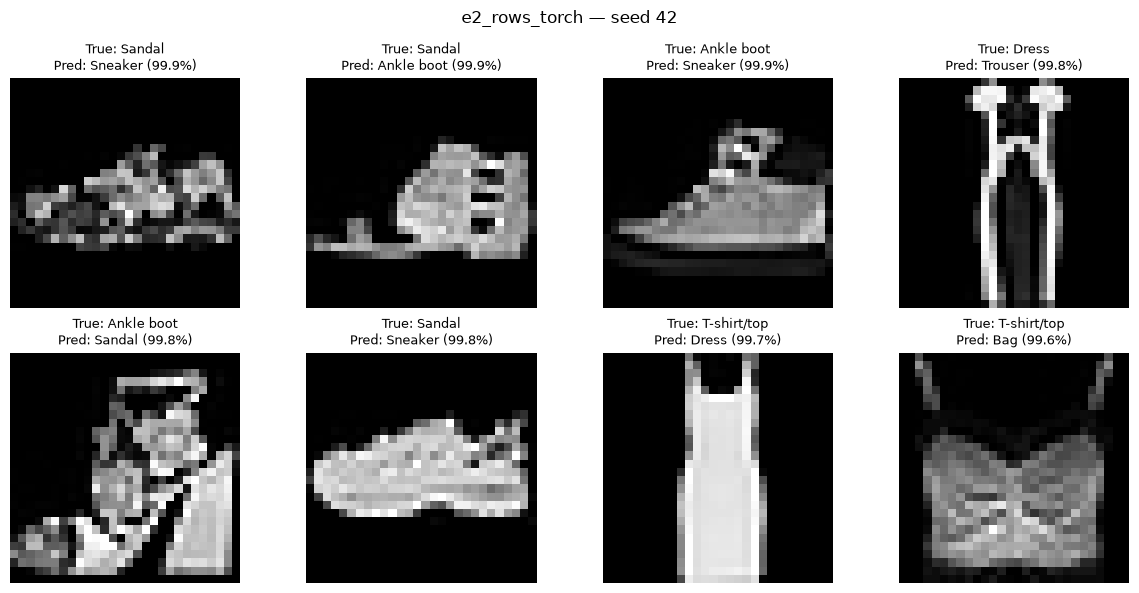

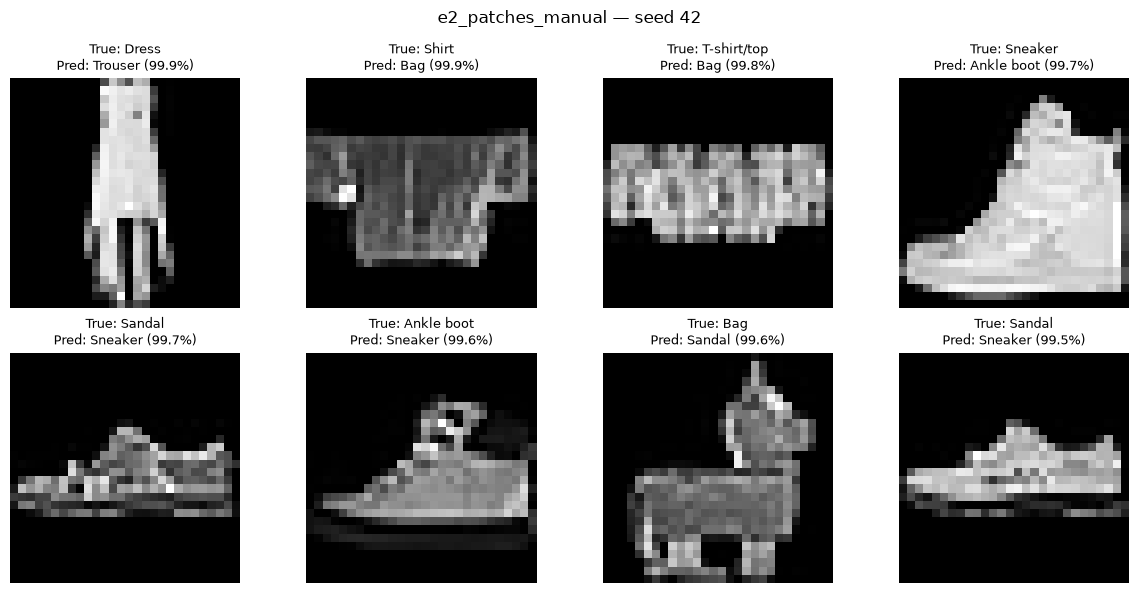

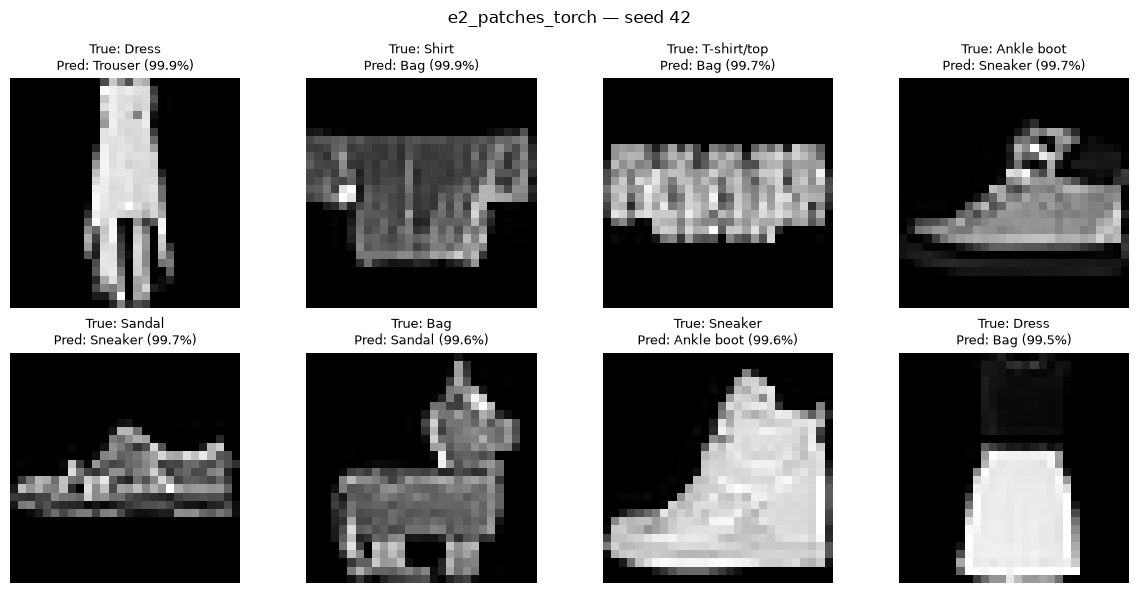

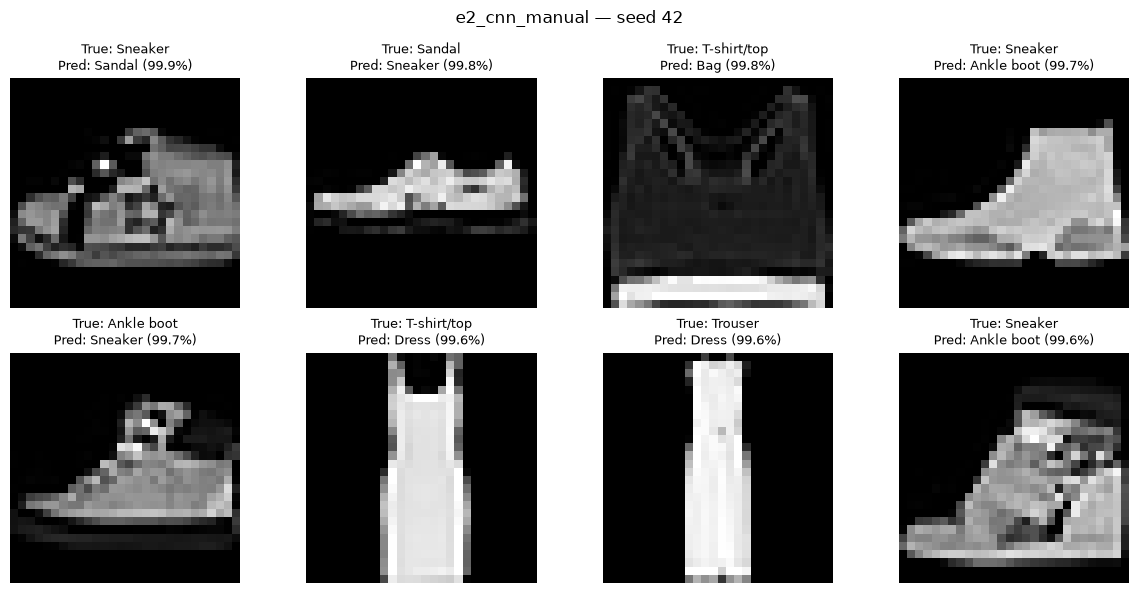

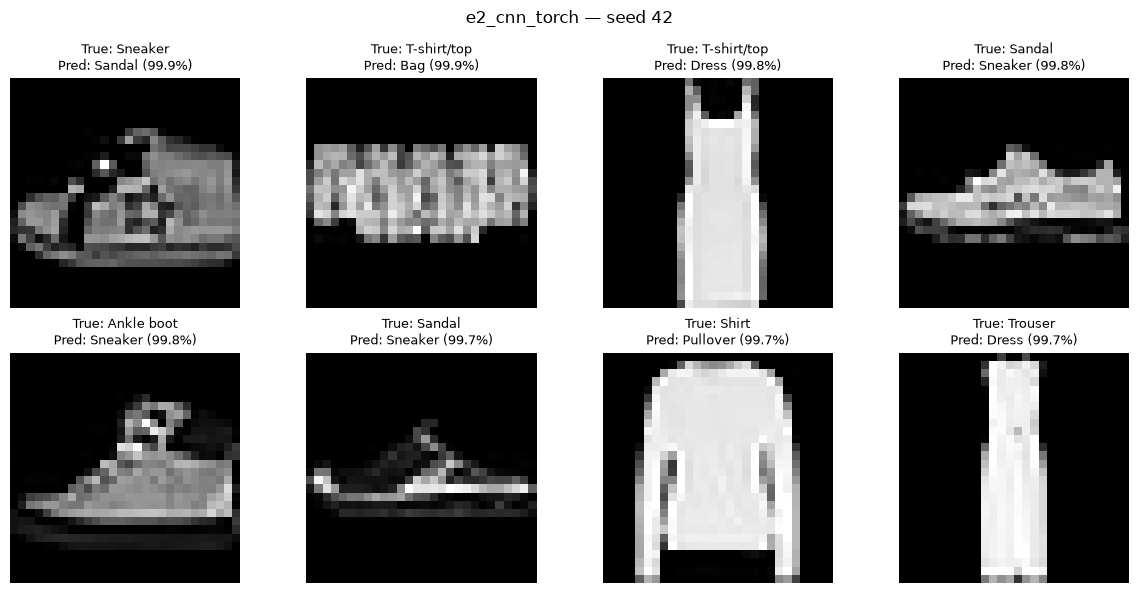

In [19]:
for config in CONFIGS:
    predictions = test_predictions[(config["id"], REPRESENTATIVE_SEED)]
    mistakes = predictions[predictions.target != predictions.prediction].sort_values(
        ["confidence", "index"], ascending=[False, True]).head(8)
    directory = RUN_DIR / config["id"] / f"seed_{REPRESENTATIVE_SEED}"
    mistakes.to_csv(directory / "representative_errors.csv", index=False)
    if mistakes.empty:
        print(config["id"], ": no misclassified test images.")
        continue
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, mistake) in zip(axes.flat, mistakes.iterrows()):
        ax.imshow(base_test.data[int(mistake["index"])], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"True: {CLASS_NAMES[int(mistake.target)]}\n"
                     f"Pred: {CLASS_NAMES[int(mistake.prediction)]} ({mistake.confidence:.1%})", fontsize=9)
    fig.suptitle(f"{config['id']} — seed {REPRESENTATIVE_SEED}")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "figures" / f"errors_{config['id']}_seed42.png", dpi=160)
    plt.show()

## 12. Findings

CNN-stem attention gives the highest mean test accuracy: **88.70 ± 0.61%** for manual attention and **88.64 ± 0.33%** for PyTorch attention. Row tokenization reaches **87.96 ± 0.16%** and **87.99 ± 0.16%**, while both patch models reach **86.02%**.

The paired PyTorch-minus-manual differences are **+0.033 ± 0.124** percentage points for rows, **0.000 ± 0.050** for patches and **−0.060 ± 0.302** for the CNN stem. These differences are small relative to variation across seeds and do not show a consistent accuracy advantage for either implementation.

The CNN stem improves feature extraction but raises parameter count from **71,370** for rows and **71,946** for patches to **89,770**. Its accuracy advantage should be read alongside that change in architecture.

In [20]:
means = results.groupby("id")[["test_accuracy", "test_macro_f1", "seconds_per_epoch"]].mean()
leader = means.test_accuracy.idxmax()
print(f"Highest mean test accuracy: {leader}, {means.loc[leader, 'test_accuracy']:.2%}.")
for tokenizer, group in paired.groupby("tokenizer"):
    print(f"{tokenizer}: PyTorch minus manual accuracy = {group.accuracy_delta_pp.mean():+.3f} "
          f"± {group.accuracy_delta_pp.std(ddof=1):.3f} percentage points; "
          f"mean time ratio = {group.native_over_manual_time.mean():.3f}.")
for config in CONFIGS:
    gaps = []
    for seed in SEEDS:
        best_epoch = int(results[(results.id == config["id"]) & (results.seed == seed)].best_epoch.iloc[0])
        best_row = histories[(config["id"], seed)].iloc[best_epoch - 1]
        gaps.append(best_row.train_accuracy - best_row.val_accuracy)
    print(f"{config['id']}: mean train-minus-validation accuracy at selected epoch = {100 * np.mean(gaps):+.2f} pp.")
print("Artifacts saved under:", RUN_DIR.resolve())

Highest mean test accuracy: e2_cnn_manual, 88.70%.
cnn: PyTorch minus manual accuracy = -0.060 ± 0.302 percentage points; mean time ratio = 0.999.
patches: PyTorch minus manual accuracy = +0.000 ± 0.050 percentage points; mean time ratio = 1.009.
rows: PyTorch minus manual accuracy = +0.033 ± 0.124 percentage points; mean time ratio = 0.997.
e2_rows_manual: mean train-minus-validation accuracy at selected epoch = +1.03 pp.
e2_rows_torch: mean train-minus-validation accuracy at selected epoch = +1.03 pp.
e2_patches_manual: mean train-minus-validation accuracy at selected epoch = +0.55 pp.
e2_patches_torch: mean train-minus-validation accuracy at selected epoch = +0.47 pp.
e2_cnn_manual: mean train-minus-validation accuracy at selected epoch = +1.44 pp.
e2_cnn_torch: mean train-minus-validation accuracy at selected epoch = +1.36 pp.
Artifacts saved under: /workspace/coursework/runs/E2/20261107T181821468703Z
